# Экзаменационная задача №10. Выбор модели координации для разработки государственной ИС

**Дисциплина:** Экономика информатизации, лекция №11
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №10: ВЫБОР МОДЕЛИ КООРДИНАЦИИ ДЛЯ РАЗРАБОТКИ ГОСУДАРСТВЕННОЙ ИС
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №11)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Нужно разработать госсистему «Единая платформа цифровых услуг»: 3 года, интеграция с 20 внешними системами, персональные данные.
Надо выбрать **модель координации**: делать самим (иерархия), отдать подрядчикам (рынок) или смешать (гибрид).
По теории транзакционных издержек (Коуз, Уильямсон) важны не только прямые затраты, но и расходы на заключение и контроль
договоров, а ещё специфичность активов, неопределённость и частота сделок.

**Цель:** сравнить варианты по TCO с учётом транзакционных издержек и по неденежным критериям, выбрать модель,
предложить, как снизить транзакционные издержки и риски.

Тема лекции №11: транзакционные издержки, «делать или покупать», специфичность активов, оппортунизм, неполные контракты.

## 2. Исходные данные

In [2]:
# 1.1. Затраты вариантов, млн руб./год (из условия)
hier = {"Зарплаты (150 чел.)": 300, "Оборудование": 30, "ПО": 20, "Администрирование": 50}
market = {"Подрядчики (3 компании)": 350, "Управление контрактами": 20, "Контроль качества": 15, "Юридическое сопровождение": 15}
hybrid = {"In-house ядро (50 чел.)": 100, "Аутсорсинг модулей (2 компании)": 200, "Интеграция": 50, "Контроль": 30}
years = 3; budget = 500; lifetime = 10
tc_rate = {"Иерархия": 0.0, "Рынок": 0.15, "Гибрид": 0.08}
contract_value = {"Иерархия": 0, "Рынок": market["Подрядчики (3 компании)"], "Гибрид": hybrid["Аутсорсинг модулей (2 компании)"]}
pd.DataFrame({"Иерархия": pd.Series(hier), "Рынок": pd.Series(market), "Гибрид": pd.Series(hybrid)}).fillna("")

,Иерархия,Рынок,Гибрид
In-house ядро (50 чел.),,,100.00
Администрирование,50.00,,
Аутсорсинг модулей (2 компании),,,200.00
Зарплаты (150 чел.),300.00,,
Интеграция,,,50.00
Контроль,,,30.00
Контроль качества,,15.00,
Оборудование,30.00,,
ПО,20.00,,
Подрядчики (3 компании),,350.00,


**Допущения:**
- Транзакционные издержки считаем **от стоимости контракта**, как сказано в условии: для рынка от оплаты подрядчиков
  (350 млн руб. в год), для гибрида от аутсорсинга модулей (200 млн руб. в год). Вариант «от всех затрат» показан
  для сравнения как верхняя оценка.
- У иерархии внешних транзакционных издержек нет, внутренние расходы на координацию уже в статье «Администрирование».
- Бюджет 500 млн руб. меньше затрат любого варианта за 3 года (от 1,1 млрд руб.), поэтому считаем его **годовым лимитом**:
  в 500 млн руб. в год укладываются все варианты.

## 3. Математическая модель

$$C^{3}_i = 3\cdot\sum_j c_{ij},\qquad TC_i = \tau_i\cdot 3\cdot V^{контр}_i,\qquad TCO_i = C^3_i + TC_i$$
Общая оценка: $S_i = \sum_k w_k\,s_{ik}$, где $s_{ik}$ это балл от 1 до 5 по критерию $k$, $\sum w_k = 1$.
Балл по стоимости $s_{i,стоим} = 5\cdot\min_j TCO_j / TCO_i$. Надёжность выбора проверяем, случайно меняя веса
(распределение Дирихле, 10 000 испытаний).

## 4. Реализация расчёта
### 4.1. Затраты и TCO за 3 года

In [3]:
annual = {"Иерархия": sum(hier.values()), "Рынок": sum(market.values()), "Гибрид": sum(hybrid.values())}
t = pd.DataFrame({"Затраты в год, млн": annual})
for y in range(1, years + 1):
    t[f"Год {y}"] = t["Затраты в год, млн"]
t["Затраты за 3 года"] = t["Затраты в год, млн"] * years
t["База ТИ (контракт за 3 года)"] = [contract_value[v] * years for v in t.index]
t["Ставка ТИ"] = [tc_rate[v] for v in t.index]
t["Транзакц. издержки"] = t["База ТИ (контракт за 3 года)"] * t["Ставка ТИ"]
t["TCO за 3 года"] = t["Затраты за 3 года"] + t["Транзакц. издержки"]
t["TCO (ТИ от всех затрат)"] = t["Затраты за 3 года"] * (1 + t["Ставка ТИ"])
t["Ранг TCO"] = t["TCO за 3 года"].rank().astype(int)
t["В лимите 500 млн/год"] = np.where(t["TCO за 3 года"] / years <= budget, "да", "нет")
t

,"Затраты в год, млн",Год 1,Год 2,Год 3,Затраты за 3 года,База ТИ (контракт за 3 года),Ставка ТИ,Транзакц. издержки,TCO за 3 года,TCO (ТИ от всех затрат),Ранг TCO,В лимите 500 млн/год
Иерархия,400,400,400,400,1200,0,0.00,0.00,1 200.00,1 200.00,2,да
Рынок,400,400,400,400,1200,1050,0.15,157.50,1 357.50,1 380.00,3,да
Гибрид,380,380,380,380,1140,600,0.08,48.00,1 188.00,1 231.20,1,да


In [4]:
# Дисконтированная TCO (12%) — для полноты, потоки в конце каждого года
rate = 0.12
t_pv = {v: npv([0] + [t.loc[v, "TCO за 3 года"] / years] * years, rate) for v in t.index}
print("TCO с дисконтированием 12%, млн руб.:", {k: round(v, 1) for k, v in t_pv.items()})

TCO с дисконтированием 12%, млн руб.: {'Иерархия': 960.7, 'Рынок': 1086.8, 'Гибрид': 951.1}


### 4.2. Матрица неденежных факторов

In [5]:
criteria = pd.DataFrame({
    "Иерархия": [5, 5, 2, 3], "Рынок": [2, 2, 5, 2], "Гибрид": [4, 4, 4, 4]},
    index=["Контроль над качеством и архитектурой", "Безопасность персональных данных", "Гибкость и доступ к компетенциям", "Риск срыва сроков (5 — низкий)"])
tco_ = t["TCO за 3 года"]
criteria.loc["Стоимость (TCO)"] = (5 * tco_.min() / tco_).round(2)
weights = pd.Series([0.25, 0.25, 0.15, 0.15, 0.20], index=criteria.index, name="Вес")
matrix = criteria.copy(); matrix["Вес"] = weights
score = (criteria.mul(weights, axis=0)).sum()
display(matrix)
print("Интегральная оценка:", score.round(2).to_dict())
print("Обоснование баллов: иерархия — полный контроль кода и данных, но набор 150 чел. на рынке дефицитных кадров "
      "угрожает срокам; рынок — гибкость и готовые компетенции, но высокий риск оппортунизма и утечки ПДн; "
      "гибрид — ядро и данные внутри, типовые модули у подрядчиков.")

,Иерархия,Рынок,Гибрид,Вес
Контроль над качеством и архитектурой,5.00,2.00,4.00,0.25
Безопасность персональных данных,5.00,2.00,4.00,0.25
Гибкость и доступ к компетенциям,2.00,5.00,4.00,0.15
Риск срыва сроков (5 — низкий),3.00,2.00,4.00,0.15
Стоимость (TCO),4.95,4.38,5.00,0.20


Интегральная оценка: {'Иерархия': 4.24, 'Рынок': 2.93, 'Гибрид': 4.2}
Обоснование баллов: иерархия — полный контроль кода и данных, но набор 150 чел. на рынке дефицитных кадров угрожает срокам; рынок — гибкость и готовые компетенции, но высокий риск оппортунизма и утечки ПДн; гибрид — ядро и данные внутри, типовые модули у подрядчиков.


In [6]:
# Устойчивость к выбору весов: случайные веса (Дирихле)
rng = np.random.default_rng(42)
W = rng.dirichlet(np.ones(len(weights)), size=10_000)
scores_mc = W @ criteria.values
wins = pd.Series(np.bincount(scores_mc.argmax(axis=1), minlength=3), index=criteria.columns) / len(W)
print("Доля испытаний, в которых вариант лучший:", (wins * 100).round(1).to_dict())

Доля испытаний, в которых вариант лучший: {'Иерархия': 34.7, 'Рынок': 2.1, 'Гибрид': 63.2}


### 4.3. Дополнительно: весь срок службы, 10 лет

Система служит 10 лет. После разработки (годы 1–3) её нужно сопровождать и развивать (годы 4–10). Примем:
своя команда сопровождения стоит 20 % годовых затрат разработки. При аутсорсинге сопровождение у того же подрядчика
стоит 25 % плюс транзакционные издержки и **наценка за зависимость** 10 %: заказчик привязан к подрядчику,
который один знает систему. Гибрид: 22 % плюс транзакционные издержки 8 %.

In [7]:
maint = {"Иерархия": (0.20, 0.0, 0.0), "Рынок": (0.25, 0.15, 0.10), "Гибрид": (0.22, 0.08, 0.0)}
life = {}
for v in t.index:
    share, tc, lock = maint[v]
    dev_flow = [t.loc[v, "TCO за 3 года"] / years] * years
    ops_flow = [annual[v] * share * (1 + tc + lock)] * (lifetime - years)
    life[v] = {"Разработка (PV)": npv([0] + dev_flow, rate), "Сопровождение 4–10 (PV)": npv([0] + [0] * years + ops_flow, rate)}
life = pd.DataFrame(life).T
life["Жизненный цикл, PV"] = life.sum(axis=1)
life.round(1)

,Разработка (PV),Сопровождение 4–10 (PV),"Жизненный цикл, PV"
Иерархия,960.70,259.90,1 220.60
Рынок,1 086.80,406.00,1 492.90
Гибрид,951.10,293.30,1 244.40


## 5. Визуализация результатов

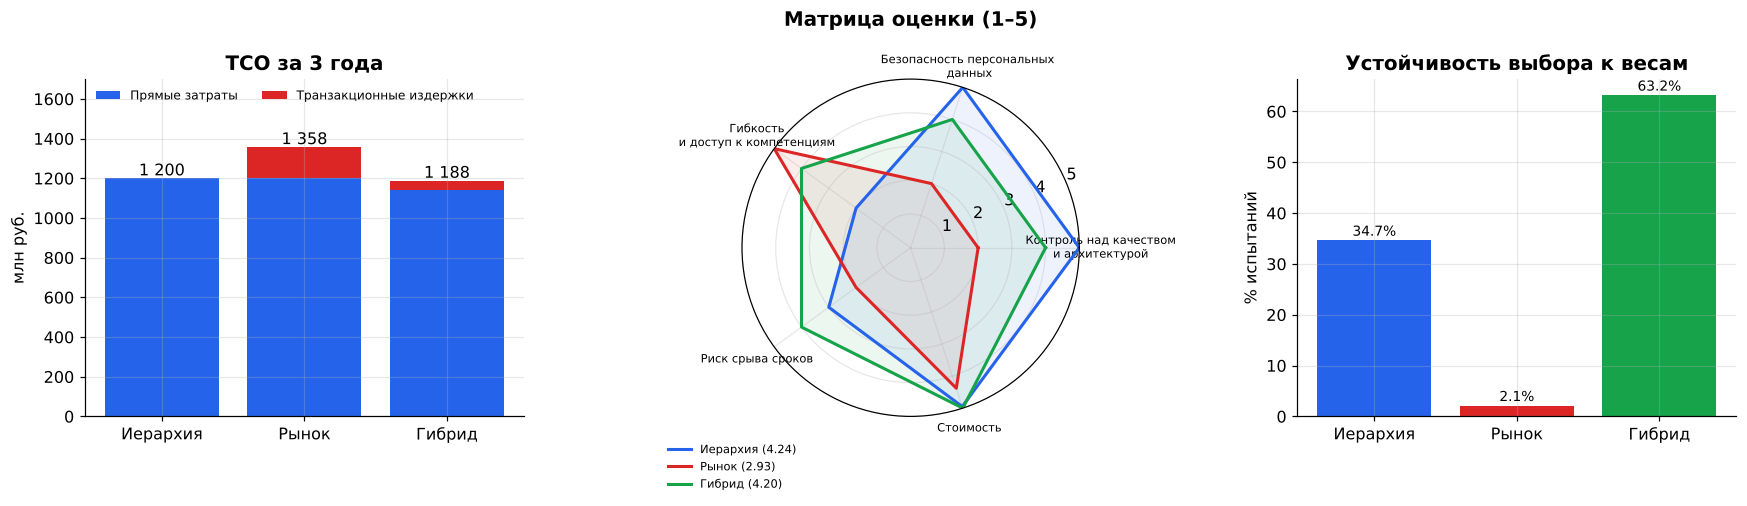

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
b1 = ax.bar(t.index, t["Затраты за 3 года"], label="Прямые затраты")
b2 = ax.bar(t.index, t["Транзакц. издержки"], bottom=t["Затраты за 3 года"], label="Транзакционные издержки")
for i, v in enumerate(t["TCO за 3 года"]): ax.text(i, v + 15, f"{v:,.0f}".replace(",", " "), ha="center")
ax.set_ylim(0, 1700); ax.set_ylabel("млн руб."); ax.set_title("TCO за 3 года"); ax.legend(fontsize=8, loc="upper left", ncol=2)
ax = axes[1]
ang = np.linspace(0, 2 * np.pi, len(criteria), endpoint=False).tolist(); ang += ang[:1]
ax.remove(); ax = fig.add_subplot(1, 3, 2, polar=True)
for v in criteria.columns:
    vals = criteria[v].tolist(); vals += vals[:1]
    ax.plot(ang, vals, lw=2, label=f"{v} ({score[v]:.2f})"); ax.fill(ang, vals, alpha=0.08)
ax.set_xticks(ang[:-1], [c.split(" (")[0].replace(" и ", "\nи ").replace("данных", "\nданных") for c in criteria.index], fontsize=7.5)
ax.set_ylim(0, 5); ax.set_title("Матрица оценки (1–5)", pad=18); ax.legend(fontsize=7.5, loc="lower left", bbox_to_anchor=(-0.25, -0.25))
ax = axes[2]
bars = ax.bar(wins.index, wins * 100, color=PALETTE[:3]); bar_labels(ax, bars, "{:.1f}%")
ax.set_ylabel("% испытаний"); ax.set_title("Устойчивость выбора к весам")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Прямые затраты** у иерархии и рынка одинаковые (400 млн руб. в год), гибрид дешевле (380 млн руб. в год).
- **Транзакционные издержки** делают рынок самым дорогим: +157,5 млн руб. за 3 года (TCO около 1 358 млн руб.).
  У гибрида они меньше (+48 млн руб.), и его TCO около **1 188 млн руб., это минимум**, даже ниже иерархии (1 200 млн руб.).
  Если считать издержки от всех затрат (верхняя оценка), гибрид (около 1 231 млн) становится вторым после иерархии,
  но разница всего 2–3 %.
- **Неденежные критерии:** иерархия лучше по контролю и безопасности, рынок по гибкости, гибрид сбалансирован.
  При базовых весах иерархия и гибрид почти равны (4,24 и 4,20, это в пределах точности экспертных баллов),
  рынок сильно отстаёт (2,93). Ничью решает проверка случайными весами: гибрид лучший примерно в 63 % испытаний,
  иерархия в 35 %, рынок в 2 %. Иерархия выигрывает, только если почти весь вес отдать контролю и безопасности.
- **На 10 годах** чистый рынок ещё хуже (PV около 1 493 млн руб. против 1 221–1 244 млн): из-за зависимости от подрядчика
  и транзакционных издержек на сопровождении гибкость превращается в постоянную переплату. На полном сроке иерархия
  чуть дешевле гибрида (примерно на 2 %), потому что сопровождение без подрядчиков не несёт транзакционных издержек.
- **По Уильямсону:** уникальная интеграция с 20 системами, персональные данные, высокая неопределённость и долгий срок
  службы говорят против рынка. Но набрать и удержать 150 разработчиков в госучреждении трудно. Поэтому лучше гибрид:
  уникальное ядро делаем сами, типовые модули отдаём подрядчикам.

## 7. Выводы и рекомендации

**Выбор: гибрид.** Самая низкая TCO разработки (около 1 188 млн руб. за 3 года), самая устойчивая общая оценка
(лучший примерно в 63 % вариантов весов), минимальный риск срыва сроков. Ядро, архитектура и персональные данные
остаются под контролем, а нужные компетенции берём на рынке. Запасной вариант иерархия: по оценке почти равна
и чуть дешевле на 10 годах, но нужно набрать 150 специалистов. Её стоит выбрать, если по требованиям безопасности
подрядчиков к системе пускать нельзя. Чтобы сопровождение в гибриде было дешевле, после 3-го года постепенно
передавать модули своей команде.

**Как снизить транзакционные издержки**
| Мера | Эффект |
|---|---|
| Типовые договоры и единые технические требования (API, стандарты кода и документации) | меньше согласований и споров |
| Приёмка по этапам с понятными критериями, автотесты | дешевле контроль качества |
| Долгие рамочные договоры с проверенными подрядчиками | меньше расходов на поиск и тендеры, меньше оппортунизма |
| Рейтинг подрядчиков | стимул работать добросовестно |
| Код, документация и права на ПО у заказчика | меньше зависимость от подрядчика |

**План управления рисками**
| Риск | Вероятность | Влияние | Что делать |
|---|---|---|---|
| Утечка персональных данных через подрядчика | средняя | высокое | ПДн только во внутреннем контуре, обезличенные тестовые данные, NDA, аудит доступа |
| Подрядчик срывает сроки | высокая | высокое | штрафы, оплата по этапам, запасной подрядчик для критичных модулей |
| Модули плохо стыкуются | средняя | высокое | своя команда интеграции и архитектор, договорённости по API |
| Не хватает людей для ядра | средняя | среднее | конкурентная зарплата, обучение, часть задач подрядчикам |
| Затраты растут | средняя | среднее | резерв 10–15 %, контроль освоенного объёма |